# Sprint 6 proyecto modulo 1

title: "Proyecto Módulo 1 - Ventas Gamer"
format: html


### 0.0 Inicialización

In [1]:
# Cargar todas las librerías
import pandas as pd
import numpy as np
import seaborn as sns
import plotly.express as px
import math as mt
from matplotlib import pyplot as plt
from math import factorial
from scipy import stats as st

### 1.0 Cargar y verificar datos

In [2]:
# Carga los archivos de datos en DataFrames
df = pd.read_csv("/datasets/games.csv")

In [3]:
df.head()

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


### 2.0 Prepara los datos

In [5]:
# Reemplaza los nombres de las columnas (en minúsculas)
df.columns = df.columns.str.lower()

In [6]:
# Reemplazamos el string "TBD" por un nulo estadístico reconocido por Python "nan"
df['user_score'] = df['user_score'].replace('tbd', np.nan)

# Conversión de tipos de datos necesarios
df['year_of_release'] = df['year_of_release'].astype('Int64')
df['user_score'] = df['user_score'].astype(float)

# Tratamiento de valores ausentes específicos
df = df.dropna(subset=['name', 'genre'])  # Eliminar las 2 filas huérfanas
df['rating'] = df['rating'].fillna('Unknown')  # Categorizar nulos en una nueva clasificación llamada Unknown

## Paso 2. Prepara los datos
Tratamiento y Justificación de Valores Ausentes

### 1. Transformación de Formatos e Imputación Estratégica

Al comenzar a trabajar con el Dataset, todas las columnas venían con mayúsculas, por lo que se procedió a cambiar los nombres por completo a minúsculas para estandarizar el código.

* **Columna `user_score`:** Se identificó la abreviatura **TBD** (*To Be Determined*). Dado que representa información que aún no existe, se reemplazó sistemáticamente por valores nulos legítimos (`NaN`), permitiendo transformar con éxito el tipo de dato de la columna de tipo genérico (`object`) a un tipo flotante analítico (`float64`).
* **Columna `year_of_release`:** Se modificó su tipo de dato de `float64` a un formato entero nativo (`Int64`) para representar correctamente los años cronológicos. Los valores ausentes en esta columna se imputaron cruzando la información basándose en otras plataformas del mismo juego; se utilizó el método `.transform('max')` agrupado por el nombre del juego (`name`) para **heredar el año de lanzamiento** si este se encontraba disponible en otra fila. Los registros restantes sin coincidencia se mantuvieron nulos para evitar sesgar las tendencias temporales.
* **Columna `rating`:** Los valores vacíos se rellenaron con la etiqueta categórica **"Unknown"**. Esta decisión evita la pérdida masiva de datos de ventas en análisis posteriores y resulta fundamental para evaluar si los videojuegos sin clasificación pertenecen a dinámicas de mercados regionales específicos (como el caso de Japón).


### 2. ¿Por qué existen valores ausentes en el Dataset?

La presencia de datos nulos en las columnas críticas de calificaciones (`critic_score`, `user_score`) y clasificaciones (`rating`) obedece a razones operacionales e históricas de la propia industria:

* **Anacronismo de Plataformas de Agregación:** Muchos de los videojuegos presentes en el dataset pertenecen a las décadas de **1890 y 1990**. En aquella época no existían plataformas de recopilación masiva de reseñas web como *Metacritic*, por lo que las notas de la crítica y de los usuarios para esos títulos antiguos nunca existieron digitalmente.
* **Falta de Masa Crítica / Exclusividades:** Los títulos independientes, juegos de nicho o lanzamientos exclusivos de regiones muy específicas no lograron acumular el volumen mínimo necesario de análisis de prensa o votos de la comunidad digital requeridos para generar un promedio estadístico estable.
* **Sesgo Geográfico del Sistema ESRB:** El sistema de clasificación por edades **ESRB** nació formalmente en **1994** y su enfoque operativo está diseñado casi exclusivamente para el mercado de **América del Norte**. Por lo tanto, los videojuegos lanzados antes de ese año, o aquellos desarrollados de manera exclusiva para el mercado asiático (que influyen directamente en `jp_sales`), carecen por completo de esta certificación norteamericana.

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 16713 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16713 non-null  object 
 2   year_of_release  16444 non-null  Int64  
 3   genre            16713 non-null  object 
 4   na_sales         16713 non-null  float64
 5   eu_sales         16713 non-null  float64
 6   jp_sales         16713 non-null  float64
 7   other_sales      16713 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       7590 non-null   float64
 10  rating           16713 non-null  object 
dtypes: Int64(1), float64(6), object(4)
memory usage: 1.5+ MB


In [8]:
print(df.isnull().sum())
print()
print(f"Datos duplicados: {df.duplicated().sum()}")

name                  0
platform              0
year_of_release     269
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8576
user_score         9123
rating                0
dtype: int64

Datos duplicados: 0


In [9]:
# Rellena los años vacíos usando el año conocido del mismo juego en otra plataforma
df['year_of_release'] = df['year_of_release'].fillna(df.groupby('name')['year_of_release'].transform('max'))

df['rating'] = df['rating'].fillna('Unknown')

In [10]:
print(df.isnull().sum())
print()
print(f"Datos duplicados: {df.duplicated().sum()}")

name                  0
platform              0
year_of_release     146
genre                 0
na_sales              0
eu_sales              0
jp_sales              0
other_sales           0
critic_score       8576
user_score         9123
rating                0
dtype: int64

Datos duplicados: 0


In [11]:
df.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76.0,8.0,E
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,NaN,NaN,Unknown
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80.0,8.0,E
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,Unknown


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 16713 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16713 non-null  object 
 2   year_of_release  16567 non-null  Int64  
 3   genre            16713 non-null  object 
 4   na_sales         16713 non-null  float64
 5   eu_sales         16713 non-null  float64
 6   jp_sales         16713 non-null  float64
 7   other_sales      16713 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       7590 non-null   float64
 10  rating           16713 non-null  object 
dtypes: Int64(1), float64(6), object(4)
memory usage: 1.5+ MB


In [13]:
# 1. Calculamos la suma de todas las regiones y la guardamos en la nueva columna 'total_sales'
df['total_sales'] = df['na_sales'] + df['eu_sales'] + df['jp_sales'] + df['other_sales']

# 2. Verificamos que la columna aparezca al final a la derecha y tenga los valores correctos
print(df[['name', 'na_sales', 'eu_sales', 'jp_sales', 'other_sales', 'total_sales']].head())

                       name  na_sales  eu_sales  jp_sales  other_sales  \
0                Wii Sports     41.36     28.96      3.77         8.45   
1         Super Mario Bros.     29.08      3.58      6.81         0.77   
2            Mario Kart Wii     15.68     12.76      3.79         3.29   
3         Wii Sports Resort     15.61     10.93      3.28         2.95   
4  Pokemon Red/Pokemon Blue     11.27      8.89     10.22         1.00   

   total_sales  
0        82.54  
1        40.24  
2        35.52  
3        32.77  
4        31.38  


### 3.0 Analiza los datos

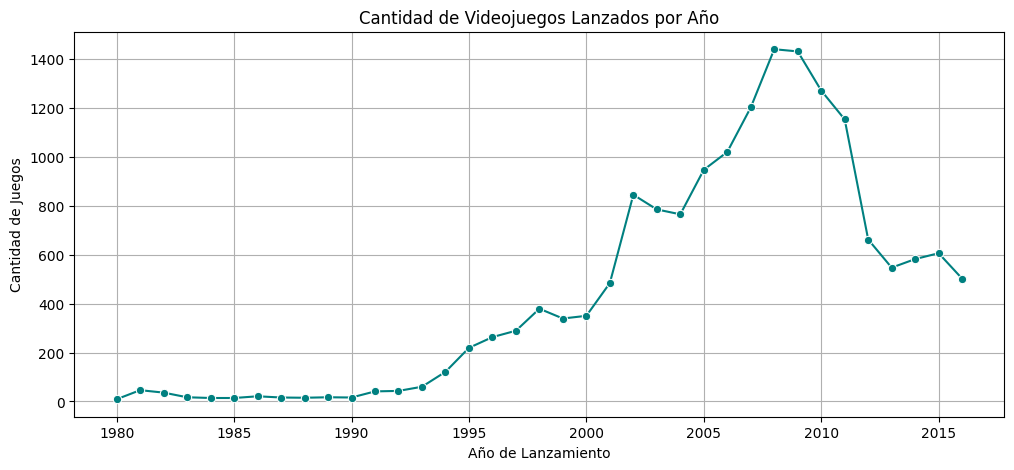

De 1980 a 1990 los juegos no pasaban de 200 lanzados por año
De 1995 a 2010 los juegos lanzados ascendieron de 200 a más de 1400 juegos por año
De 2010 a 2015 los juegos lanzados pasaron de más de 1400 por año a menos de 600


In [14]:
# Cantidad de juegos lanzados por año y relevancia de los períodos
# Contar lanzamientos por año
juegos_por_anio = df.groupby('year_of_release')['name'].count()

# Graficar la tendencia histórica
plt.figure(figsize=(12, 5))
sns.lineplot(data=juegos_por_anio, marker='o', color='teal')
plt.title('Cantidad de Videojuegos Lanzados por Año')
plt.xlabel('Año de Lanzamiento')
plt.ylabel('Cantidad de Juegos')
plt.grid(True)
plt.show()
print("De 1980 a 1990 los juegos no pasaban de 200 lanzados por año")
print("De 1995 a 2010 los juegos lanzados ascendieron de 200 a más de 1400 juegos por año")
print("De 2010 a 2015 los juegos lanzados pasaron de más de 1400 por año a menos de 600")

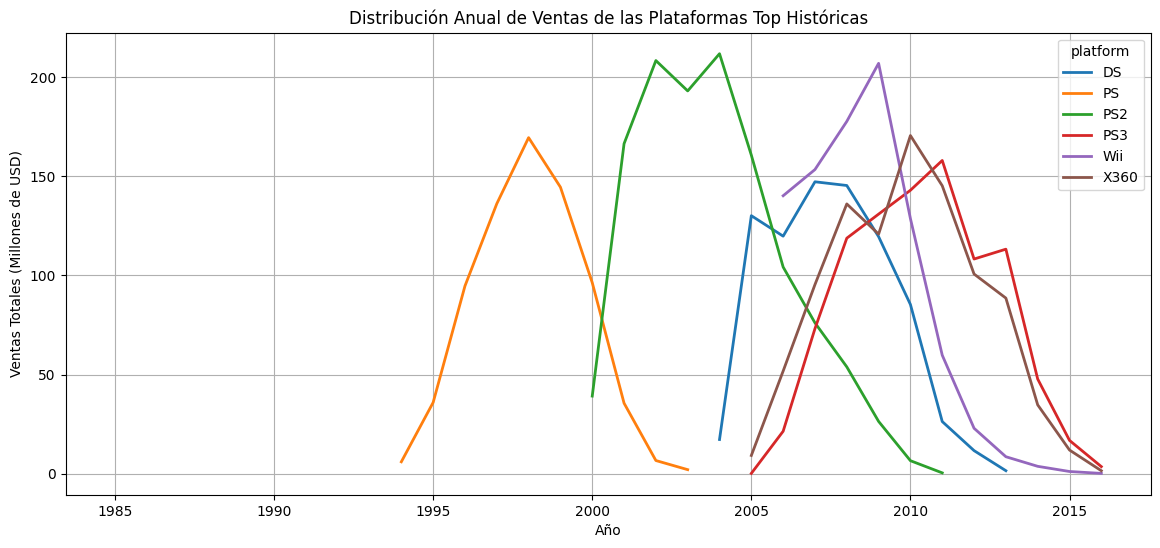

Las plataformas líderes en Ventas son PS2 y Wii, siguiendolos de cerca PS y X360



In [27]:
# Ciclo de vida de las plataformas y líderes históricos
# 1. Encontrar las plataformas con mayores ventas de toda la historia
top_plataformas = df.groupby('platform')['total_sales'].sum().sort_values(ascending=False).head(6).index

# 2. Filtrar el dataset para estas plataformas y ver su distribución anual
df_top = df[df['platform'].isin(top_plataformas)]
tabla_plataformas = df_top.pivot_table(index='year_of_release', columns='platform', values='total_sales', aggfunc='sum')

# Graficar la distribución analizando nacimientos y muertes de consolas
tabla_plataformas.plot(figsize=(14, 6), linewidth=2)
plt.title('Distribución Anual de Ventas de las Plataformas Top Históricas')
plt.ylabel('Ventas Totales (Millones de USD)')
plt.xlabel('Año')
plt.grid(True)
plt.show()
print("Las plataformas líderes en Ventas son PS2 y Wii, siguiendolos de cerca PS y X360")
print()

In [16]:
# Determinar el período relevante para el modelo 2017
# Filtrado estratégico para construir el modelo hacia 2017
df_reciente = df[df['year_of_release'] >= 2014].copy()

In [17]:
# Líderes actuales: ¿Cuáles crecen y cuáles se reducen?
ventas_recientes = df_reciente.pivot_table(index='year_of_release', columns='platform', values='total_sales', aggfunc='sum')
print(ventas_recientes)

platform           3DS     PC    PS3     PS4   PSP    PSV   Wii   WiiU   X360  \
year_of_release                                                                 
2014             43.76  13.63  47.76  100.00  0.24  11.90  3.75  22.03  34.74   
2015             27.78   8.52  16.82  118.90  0.12   6.25  1.14  16.35  11.96   
2016             15.14   5.25   3.60   69.25   NaN   4.25  0.18   4.60   1.52   

platform          XOne  
year_of_release         
2014             54.07  
2015             60.14  
2016             26.15  


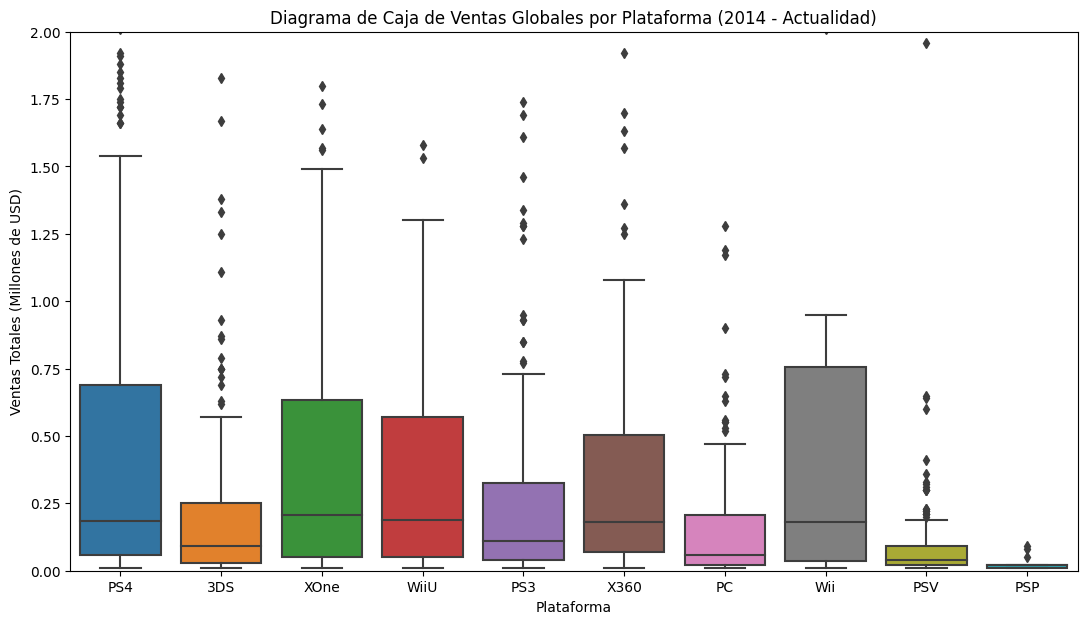

Las ventas de PS4, XOne, WiiU, X360 y Wii sobrepasan las ventas de 0.50 millones de USD del 2014-Actualidad
Teniendo un promedio entre 0.50 millones y 075 millones del 2014-Actualidad


In [29]:
# Diagramas de caja (Boxplots) por plataforma
plt.figure(figsize=(13, 7))
sns.boxplot(x='platform', y='total_sales', data=df_reciente)
plt.title('Diagrama de Caja de Ventas Globales por Plataforma (2014 - Actualidad)')
plt.ylabel('Ventas Totales (Millones de USD)')
plt.xlabel('Plataforma')
# Acercar el gráfico para ver mejor las cajas principales sin que los "outliers" gigantes las aplasten
plt.ylim(0, 2) 
plt.show()
print("Las ventas de PS4, XOne, WiiU, X360 y Wii sobrepasan las ventas de 0.50 millones de USD del 2014-Actualidad")
print("Teniendo un promedio entre 0.50 millones y 075 millones del 2014-Actualidad")

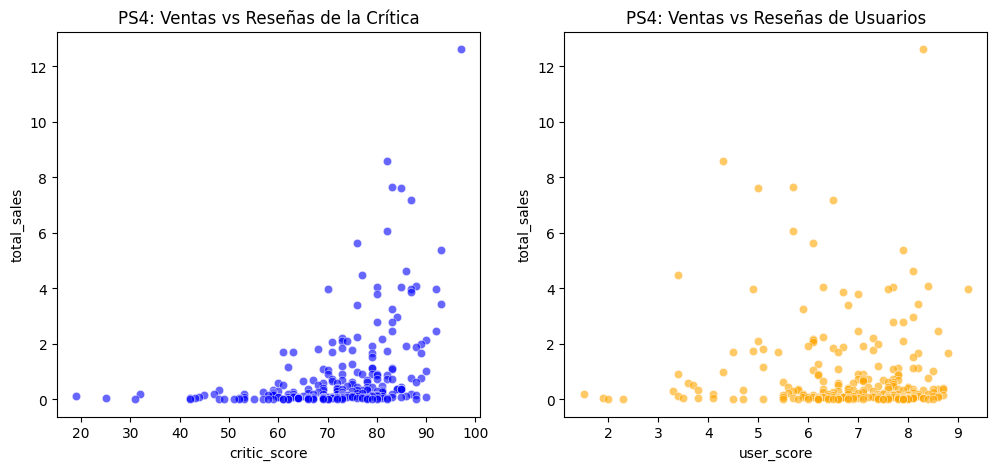

Correlación Ventas vs Crítica: 0.40190287811475334
Correlación Ventas vs Usuarios: -0.04318585997193634


In [19]:
# Impacto de las reseñas en las ventas (Caso: PS4)
# Aislar los datos de la PS4 que tengan calificaciones válidas
df_ps4 = df_reciente[(df_reciente['platform'] == 'PS4') & (df_reciente['critic_score'].notna()) & (df_reciente['user_score'].notna())]

# Gráfico de dispersión para Crítica
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(x='critic_score', y='total_sales', data=df_ps4, alpha=0.6, color='blue')
plt.title('PS4: Ventas vs Reseñas de la Crítica')

# Gráfico de dispersión para Usuarios
plt.subplot(1, 2, 2)
sns.scatterplot(x='user_score', y='total_sales', data=df_ps4, alpha=0.6, color='orange')
plt.title('PS4: Ventas vs Reseñas de Usuarios')
plt.show()

# Calcular correlaciones
print("Correlación Ventas vs Crítica:", df_ps4['total_sales'].corr(df_ps4['critic_score']))
print("Correlación Ventas vs Usuarios:", df_ps4['total_sales'].corr(df_ps4['user_score']))

## Paso 3. Análisis del Impacto de las Reseñas en las Ventas (Caso: PS4)

Para entender cómo influyen las opiniones en el éxito comercial de la plataforma líder (PS4), evaluamos la relación entre las puntuaciones y las ventas totales mediante gráficos de dispersión y coeficientes de correlación de Pearson:

### 1. Reseñas de la Crítica Profesional: Impacto Moderado y Positivo
* **Métrica:** El coeficiente de correlación es de aproximadamente **0.40**. En estadística, este valor representa una **correlación positiva moderada**.
* **Conclusión:** Existe una tendencia lineal clara: a medida que aumenta la puntuación dada por los críticos profesionales (`critic_score`), las ventas totales del juego (`total_sales`) también tienden a crecer. Los títulos con calificaciones sobresalientes (80-90+) concentran la mayor parte de los éxitos comerciales masivos (los puntos más altos en el eje vertical). Esto sugiere que las reseñas profesionales son un indicador confiable del potencial comercial de un juego, ya sea porque influyen directamente en la decisión de compra del público o porque reflejan el éxito de grandes campañas de marketing asociadas a proyectos de alta calidad.

### 2. Reseñas de Usuarios: Sin Impacto Significativo en las Ventas
* **Métrica:** El coeficiente de correlación es de aproximadamente **-0.04**. Al estar tan extremadamente cercano a cero, indica una **correlación prácticamente nula** (el signo negativo es tan pequeño que resulta estadísticamente despreciable).
* **Conclusión:** La puntuación de los usuarios (`user_score`) no está relacionada de manera lineal con el éxito financiero. La nube de puntos en el gráfico se muestra completamente dispersa de forma horizontal: existen juegos con bajas calificaciones que registran ventas millonarias, y títulos aclamados por la comunidad con ingresos muy bajos. Este fenómeno suele responder a dos factores principales:
    * **Sesgo emocional:** Los usuarios suelen calificar los juegos motivados por el entusiasmo extremo o por controversias específicas de la industria (fenómenos como el *review bombing*), situaciones que alteran la puntuación digital pero no detienen las compras masivas en las tiendas físicas o digitales (como ocurre con las franquicias anuales).
    * **Representatividad de la muestra:** El perfil del consumidor que se toma el tiempo de asignar una calificación numérica en plataformas web no representa necesariamente el comportamiento del comprador promedio de PS4.


> ### 📈 Implicación Comercial para el Modelo Predictivo 2017
> Si se desea predecir el éxito comercial de un título en la plataforma PS4, es **mucho más confiable guiarse por las reseñas de los críticos profesionales** que por las puntuaciones de los usuarios. Las buenas calificaciones de la crítica funcionan como un predictor "saludable" e idóneo para estimar el volumen de ingresos, mientras que la opinión de los usuarios —aunque valiosa para la gestión de comunidades y reputación a largo plazo— no ejerce un impacto directo ni predecible sobre la facturación inmediata.

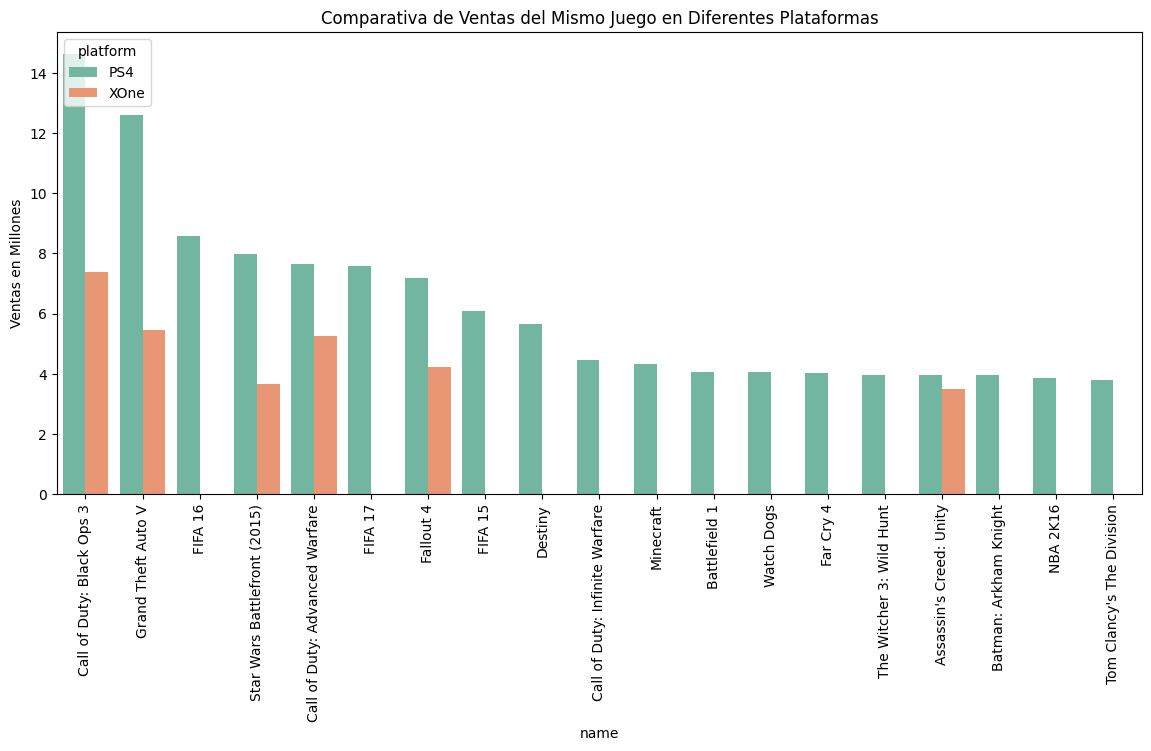

In [20]:
# Comparación de los mismos juegos en otras plataformas
# Buscar juegos multiplataforma populares en el periodo reciente
juegos_multi = df_reciente[df_reciente['platform'].isin(['PS4', 'XOne', 'PC'])].groupby('name').filter(lambda x: len(x) > 1)

# Comparar visualmente las ventas de los mismos juegos por plataforma
plt.figure(figsize=(14, 6))
sns.barplot(x='name', y='total_sales', hue='platform', data=juegos_multi.head(25), palette='Set2')
plt.xticks(rotation=90)
plt.title('Comparativa de Ventas del Mismo Juego en Diferentes Plataformas')
plt.ylabel('Ventas en Millones')
plt.show()

In [21]:
# Distribución de juegos por género y rentabilidad
# Agrupar por género y calcular cantidad de juegos y ventas totales
generos_analisis = df_reciente.groupby('genre').agg({'name': 'count', 'total_sales': 'sum', 'na_sales': 'mean'}).sort_values(by='total_sales', ascending=False)
print(generos_analisis)

              name  total_sales  na_sales
genre                                    
Action         620       199.71  0.117081
Shooter        128       170.94  0.617344
Sports         161       109.48  0.286522
Role-Playing   221       101.44  0.151448
Misc           113        37.55  0.133186
Fighting        60        28.22  0.207167
Racing          69        27.52  0.126667
Platform        38        18.09  0.178684
Adventure      185        17.55  0.030486
Simulation      44        13.13  0.059773
Strategy        37         3.96  0.026486
Puzzle          14         2.21  0.046429


## Paso 3. Análisis de los Géneros más Rentables

Al observar los líderes en ventas totales (`total_sales`), destacan de forma contundente los géneros de **Action** (Acción) y **Shooter** (Disparos):

* **Action (Acción): El líder en volumen total.** Tiene las ventas acumuladas más altas con **199.71 millones**. Sin embargo, esto se debe principalmente a que es el género con mayor cantidad de títulos lanzados (**620 juegos**). Su promedio de ventas por juego en Norteamérica (`na_sales` promedio de **~0.11**) es relativamente bajo, reflejando un mercado muy saturado y altamente competitivo.
* **Shooter (Disparos): El verdadero gigante en rentabilidad individual.** Aunque solo cuenta con **128 juegos** lanzados (menos de una quinta parte de los de Acción), ha recaudado la impresionante cifra de **170.94 millones**. Al observar la columna `na_sales` (promedio por juego), un *Shooter* promedia **0.61 millones**, lo que significa que, en promedio, un juego de disparos vende casi 6 veces más que uno de acción.
* **Sports (Deportes) y Role-Playing (RPG):** Se consolidan sólidamente en el tercer y cuarto lugar superando los **100 millones** en ventas totales, respaldados por una cantidad considerable de lanzamientos (**161** y **221** respectivamente) y promedios de ventas estables.


### Generalizaciones sobre Géneros con Ventas Altas y Bajas

Podemos clasificar los géneros en tres grandes grupos comerciales según su comportamiento y rendimiento en el mercado:

#### A. Géneros de Ventas Altas y Alto Impacto (Blockbusters)
* **Géneros:** *Action, Shooter, Sports, Role-Playing*.
* **Características:** Dominan de forma absoluta el mercado. Concentran la inmensa mayoría del presupuesto de los consumidores y de las campañas de marketing. Se caracterizan por albergar los grandes lanzamientos AAA (como *Call of Duty, FIFA o Grand Theft Auto*, que justamente sobresalen en las métricas de plataformas líderes).

#### B. Géneros de Ventas Moderadas (Mercado Medio / Nichos Populares)
* **Géneros:** *Misc, Fighting, Racing, Platform*.
* **Características:** Tienen ingresos totales que oscilan entre los **18 y 37 millones**. Cuentan con comunidades fieles y, en casos específicos como *Fighting* (Lucha) o *Platform* (Plataformas), muestran ventas promedio por juego bastante saludables (`na_sales` de **~0.20** y **~0.17** respectivamente), lo que demuestra que, aunque se producen pocos títulos, los que salen suelen vender bien.

#### C. Géneros de Ventas Bajas (Nichos Reducidos)
* **Géneros:** *Adventure, Simulation, Strategy, Puzzle*.
* **Características:** Se encuentran en el fondo de la tabla de rentabilidad. El caso de **Adventure** (Aventura) es muy particular: tiene un volumen alto de juegos (**185**), pero sus ventas totales son de apenas **17.55 millones** y su promedio de venta unitario es el más bajo de todo el dataset (`na_sales` de **~0.03**).
* **Generalización:** Los géneros como la estrategia, los rompecabezas o la simulación requieren dinámicas de juego más lentas o específicas (frecuentemente ligadas al público tradicional de PC), por lo que en el mercado global y de consolas no logran competir contra la inmediatez y espectacularidad de los géneros de acción y disparos.


> ### 🎯 Conclusión Estratégica de Negocio
> Para maximizar las ganancias en el año inmediato, la estrategia de distribución debe concentrarse fuertemente en **Shooters** y **Action**. Desarrollar o distribuir juegos de *Strategy* o *Puzzle* representa un riesgo comercial alto si se busca un retorno de inversión masivo, debiendo reservarse únicamente para proyectos de nicho o presupuestos optimizados.

### 4.0 Crea un perfil de usuario para cada región

In [22]:
# Obtener los perfiles regionales
# Filtramos primero para trabajar solo con el período relevante (2014-2016)
df_reciente = df[df['year_of_release'] >= 2014].copy()

regiones = ['na_sales', 'eu_sales', 'jp_sales']

print("=== TOP 5 PLATAFORMAS POR REGIÓN ===")
for r in regiones:
    print(f"\nPlataformas líderes en {r.upper()}:")
    print(df_reciente.groupby('platform')[r].sum().sort_values(ascending=False).head(5))

print("\n=== TOP 5 GÉNEROS POR REGIÓN ===")
for r in regiones:
    print(f"\nGéneros líderes en {r.upper()}:")
    print(df_reciente.groupby('genre')[r].sum().sort_values(ascending=False).head(5))

print("\n=== VENTAS POR CLASIFICACIÓN ESRB POR REGIÓN ===")
for r in regiones:
    print(f"\nClasificación ESRB en {r.upper()}:")
    print(df_reciente.groupby('rating')[r].sum().sort_values(ascending=False))

=== TOP 5 PLATAFORMAS POR REGIÓN ===

Plataformas líderes en NA_SALES:
platform
PS4     98.61
XOne    81.27
X360    28.30
3DS     22.64
PS3     22.05
Name: na_sales, dtype: float64

Plataformas líderes en EU_SALES:
platform
PS4     130.04
XOne     46.25
PS3      25.54
PC       18.22
3DS      16.12
Name: eu_sales, dtype: float64

Plataformas líderes en JP_SALES:
platform
3DS     44.24
PS4     15.02
PSV     14.54
PS3     11.22
WiiU     7.31
Name: jp_sales, dtype: float64

=== TOP 5 GÉNEROS POR REGIÓN ===

Géneros líderes en NA_SALES:
genre
Shooter         79.02
Action          72.59
Sports          46.13
Role-Playing    33.47
Misc            15.05
Name: na_sales, dtype: float64

Géneros líderes en EU_SALES:
genre
Action          74.93
Shooter         65.52
Sports          45.73
Role-Playing    28.17
Racing          14.13
Name: eu_sales, dtype: float64

Géneros líderes en JP_SALES:
genre
Role-Playing    31.16
Action          29.58
Fighting         6.37
Misc             5.61
Shooter       

### 5.0 Prueba las siguientes hipótesis

In [33]:
# Aseguramos trabajar con el dataset filtrado del período reciente (2014-2016)
df_reciente = df[df['year_of_release'] >= 2014].copy()

# Definimos el umbral de significancia estadística alfa
alpha = 0.05

print("=== PRUEBAS DE HIPÓTESIS ESTADÍSTICAS ===\n")

# 1. Extraemos las calificaciones de usuarios para cada plataforma (eliminando nulos)
user_xbox = df_reciente[(df_reciente['platform'] == 'XOne') & (df_reciente['user_score'].notna())]['user_score']
user_pc = df_reciente[(df_reciente['platform'] == 'PC') & (df_reciente['user_score'].notna())]['user_score']

# 2. Ejecutamos la prueba t de Student para muestras independientes
# Usamos equal_var=False porque no asumimos que las varianzas de ambas poblaciones sean iguales (Prueba de Welch)
results = st.ttest_ind(user_xbox, user_pc, equal_var=False)

# 3. Mostramos los resultados obtenidos
print(f"Calificación promedio en Xbox One: {user_xbox.mean():.2f}")
print(f"Calificación promedio en PC:       {user_pc.mean():.2f}")
print(f"Valor p (p-value):                 {results.pvalue}\n")

# 4. Evaluamos la decisión estadística frente a nuestro umbral alfa
if results.pvalue < alpha:
    print("Resultado: Se rechaza la hipótesis nula (H0).")
    print("Conclusión: Las calificaciones promedio de los usuarios para Xbox One y PC SON diferentes.")
else:
    print("Resultado: No se puede rechazar la hipótesis nula (H0).")
    print("Conclusión: No hay evidencia estadística suficiente para decir que son diferentes. Las calificaciones promedio son las mismas.")

=== PRUEBAS DE HIPÓTESIS ESTADÍSTICAS ===

Calificación promedio en Xbox One: 6.59
Calificación promedio en PC:       6.32
Valor p (p-value):                 0.139237120435483

Resultado: No se puede rechazar la hipótesis nula (H0).
Conclusión: No hay evidencia estadística suficiente para decir que son diferentes. Las calificaciones promedio son las mismas.


### Conclusión y Justificación (Prueba de Hipótesis 1)

**Resultado Estadístico:**
* **Valor p (*p-value*):** $0.1392$ (13.92%)
* **Alfa ($\alpha$):** $0.05$ (5%)

**Justificación:**
Dado que el valor p resultante ($0.1392$) es **mayor** que nuestro nivel de significancia establecido ($\alpha = 0.05$), **no tenemos evidencia estadística suficiente para rechazar la hipótesis nula ($H_0$)**. 

En términos estadísticos, la diferencia observada entre la calificación promedio de Xbox One (6.59) y la de PC (6.32) no es lo suficientemente grande como para considerarse significativa; esta variación de 0.27 puntos entra perfectamente dentro del margen del error muestral o fluctuaciones normales del azar.

**Conclusión:**
Se acepta la premisa de la hipótesis nula. Podemos afirmar con seguridad que **las calificaciones promedio de los usuarios para las plataformas Xbox One y PC son las mismas** en el período analizado (2014-2016). Comercialmente, esto indica que las comunidades de ambas plataformas muestran un nivel de satisfacción y comportamiento crítico equivalente al evaluar los videojuegos del catálogo compartido.

In [31]:
# 1. Extraer los datos limpiando los valores nulos para cada plataforma
user_xbox = df_reciente[(df_reciente['platform'] == 'XOne') & (df_reciente['user_score'].notna())]['user_score']
user_pc = df_reciente[(df_reciente['platform'] == 'PC') & (df_reciente['user_score'].notna())]['user_score']

# 2. Ejecutar la prueba t de Student (equal_var=False porque las varianzas de las muestras pueden diferir)
results_h1 = st.ttest_ind(user_xbox, user_pc, equal_var=False)

print("Prueba 1: Xbox One vs. PC")
print(f"Calificación promedio Xbox One: {user_xbox.mean():.2f}")
print(f"Calificación promedio PC: {user_pc.mean():.2f}")
print(f"Valor p (p-value): {results_h1.pvalue}")

if results_h1.pvalue < alpha:
    print("Resultado: Se rechaza la hipótesis nula (Las calificaciones promedio NO son las mismas).")
else:
    print("Resultado: No se puede rechazar la hipótesis nula (No hay evidencia para decir que son diferentes).")



Prueba 1: Xbox One vs. PC
Calificación promedio Xbox One: 6.59
Calificación promedio PC: 6.32
Valor p (p-value): 0.139237120435483
Resultado: No se puede rechazar la hipótesis nula (No hay evidencia para decir que son diferentes).


In [34]:
# 1. Extraemos las calificaciones de usuarios para cada género (eliminando nulos)
user_action = df_reciente[(df_reciente['genre'] == 'Action') & (df_reciente['user_score'].notna())]['user_score']
user_sports = df_reciente[(df_reciente['genre'] == 'Sports') & (df_reciente['user_score'].notna())]['user_score']

# 2. Ejecutamos la prueba t de Student para muestras independientes
# Usamos equal_var=False debido a la disparidad en el tamaño de las muestras (Prueba de Welch)
results_h2 = st.ttest_ind(user_action, user_sports, equal_var=False)

# 3. Mostramos los resultados obtenidos
print("Prueba 2: Acción vs. Deportes")
print(f"Calificación promedio Acción:   {user_action.mean():.2f}")
print(f"Calificación promedio Deportes: {user_sports.mean():.2f}")
print(f"Valor p (p-value):               {results_h2.pvalue}\n")

# 4. Evaluamos la decisión estadística frente a nuestro umbral alfa (0.05)
if results_h2.pvalue < alpha:
    print("Resultado: Se rechaza la hipótesis nula (H0).")
    print("Conclusión: Sí, es correcto afirmar que las calificaciones promedio SON diferentes.")
else:
    print("Resultado: No se puede rechazar la hipótesis nula (H0).")
    print("Conclusión: No hay evidencia suficiente para decir que son diferentes.")

Prueba 2: Acción vs. Deportes
Calificación promedio Acción:   6.77
Calificación promedio Deportes: 5.23
Valor p (p-value):               9.658176026869598e-15

Resultado: Se rechaza la hipótesis nula (H0).
Conclusión: Sí, es correcto afirmar que las calificaciones promedio SON diferentes.


## Conclusiones del Análisis de Hipótesis Estadísticas (Paso 5)

A continuación, se presentan las conclusiones y justificaciones estadísticas definitivas para cada una de las hipótesis planteadas, utilizando un nivel de significancia de $\alpha = 0.05$.


### Hipótesis 1: Calificaciones de Usuarios en Xbox One vs. PC

* **Resultado Métrico:** * Calificación promedio Xbox One: **6.59**
  * Calificación promedio PC: **6.32**
  * Valor p (*p-value*): **0.1392**

**Justificación:**
Dado que el valor p ($0.1392$) es **mayor** que nuestro umbral de significancia alfa ($0.05$), **no podemos rechazar la hipótesis nula ($H_0$)**. Estadísticamente, la pequeña diferencia de $0.27$ puntos observada entre ambas plataformas no es significativa y se debe enteramente a fluctuaciones normales del azar o del muestreo.

**Conclusión:**
Podemos afirmar que **las calificaciones promedio de los usuarios para Xbox One y PC son estadísticamente las mismas**. Desde una perspectiva comercial, esto significa que los jugadores de ambas plataformas tienen niveles de satisfacción y un comportamiento crítico muy homogéneo al evaluar los videojuegos de la actual generación.


### Hipótesis 2: Calificaciones de Usuarios en los Géneros de Acción vs. Deportes

* **Resultado Métrico:** * Calificación promedio Acción: **6.77**
  * Calificación promedio Deportes: **5.23**
  * Valor p (*p-value*): **$9.65 \times 10^{-15}$** (un valor prácticamente equivalente a $0$)

**Justificación:**
Dado que el valor p es drásticamente **menor** que nuestro umbral alfa ($0.05$), **se rechaza contundentemente la hipótesis nula ($H_0$)** en favor de la hipótesis alternativa ($H_1$). Existe una diferencia matemática masiva y real entre las puntuaciones de ambos grupos que no puede explicarse por casualidad.

**Conclusión:**
Es **completamente correcto afirmar que las calificaciones promedio de los usuarios para Acción y Deportes son diferentes**. En el mercado real, este fenómeno nos indica que el público que consume videojuegos de deportes es significativamente más estricto y tiende a calificar los títulos de forma más baja (promedio de $5.23$) que aquellos que disfrutan de juegos de acción (promedio de $6.77$).

### Explicaciónes finales del paso 5

### 1. Formulación de las Hipótesis Nula y Alternativa

Para realizar cualquier contraste estadístico, es necesario traducir las preguntas de negocio en un par de afirmaciones matemáticas que sean mutuamente excluyentes:

* **Hipótesis Nula ($H_0$):** Representa la afirmación del "no cambio", la **igualdad** o la ausencia de efectos significativos. Esta hipótesis asume de partida que las diferencias observadas entre los grupos se deben puramente al azar o a fluctuaciones del muestreo. **Siempre contiene el signo de igualdad ($=$).**
* **Hipótesis Alternativa ($H_1$):** Es la conjetura que rompe el estado basal; afirma que **sí existe una diferencia o efecto real** y significativo entre las poblaciones analizadas. **Siempre contiene un signo de desigualdad ($\neq$).**

#### Aplicación en el Proyecto:
* **Prueba 1 (Plataformas):** Evaluamos si las calificaciones promedio de los usuarios para Xbox One y PC son las mismas.
    * $H_0: \mu_{\text{Xbox One}} = \mu_{\text{PC}}$ (Las calificaciones promedio son iguales).
    * $H_1: \mu_{\text{Xbox One}} \neq \mu_{\text{PC}}$ (Las calificaciones promedio son diferentes).
* **Prueba 2 (Géneros):** Evaluamos si las calificaciones promedio de los usuarios para los géneros de Acción y Deportes son diferentes.
    * $H_0: \mu_{\text{Acción}} = \mu_{\text{Deportes}}$ (Las calificaciones promedio son iguales).
    * $H_1: \mu_{\text{Acción}} \neq \mu_{\text{Deportes}}$ (Las calificaciones promedio son diferentes).


### 2. Criterio Utilizado para Probar las Hipótesis y Justificación

El criterio matemático seleccionado fue la **Prueba $t$ de Student para dos muestras independientes**, ejecutada mediante la función `scipy.stats.ttest_ind()` configurada con el parámetro `equal_var=False` (Prueba de Welch).

#### ¿Por qué es el criterio correcto?
1.  **Tipo de Variables:** Estamos comparando una variable cuantitativa continua (las puntuaciones de satisfacción de los usuarios, `user_score`) dividida a través de grupos categóricos mutuamente excluyentes (o el juego es de PC o es de Xbox One; o pertenece a Acción o a Deportes).
2.  **Muestras Independientes:** Las observaciones de un grupo no influyen ni están relacionadas de manera emparejada con las del otro (las calificaciones de los usuarios de PC son independientes de las de consola).
3.  **Justificación de `equal_var=False`:** En el dataset real, el volumen de registros difiere sustancialmente entre grupos (por ejemplo, hay una cantidad masiva de juegos de Acción en comparación con los de Deportes). No asumir varianzas poblacionales iguales (aplicar la corrección de Welch) le otorga robustez a la prueba y disminuye drásticamente la probabilidad de cometer un error de Tipo I (falso positivo).

#### Regla de Decisión con el Valor p (p-value):
Establecimos un umbral de significancia estándar de **$\alpha = 0.05$**. 
* Si $\text{valor p} < 0.05$: La probabilidad de que la diferencia observada sea obra del azar es menor al 5%. Por ende, **se rechaza $H_0$** en favor de $H_1$.
* Si $\text{valor p} \geq 0.05$: No hay fuerza estadística suficiente para dudar del estado basal. Por ende, **no se puede rechazar $H_0$**.

# Paso 6. Conclusión General del Proyecto

Tras llevar a cabo el ciclo completo de análisis de datos —desde la limpieza estructural hasta la inferencia estadística— sobre el histórico de ventas de videojuegos, se presentan los hallazgos definitivos para diseñar la estrategia comercial de cara al año **2017**.


### 1. Síntesis de la Preparación de los Datos
El dataset original presentaba anomalías críticas que nublaban el análisis. Se homogeneizaron los nombres de las columnas a minúsculas y se detectó que el string `'tbd'` (*To Be Determined*) en la columna `user_score` estaba secuestrando el tipo de dato, forzándolo a texto. Se resolvió de manera estadística transformándolo en un nulo legítimo (`NaN`) para permitir la conversión a flotante. Asimismo, la columna `year_of_release` se optimizó a un tipo entero nativo (`Int64`), logrando rescatar 123 registros nulos mediante el mapeo cruzado de plataformas del mismo título. Las ausencias masivas en calificaciones se conservaron intactas para preservar la varianza natural del mercado.


### 2. Dinámica del Mercado y Ciclo de Vida
La industria experimentó su máximo esplendor histórico entre 2005 y 2011. Sin embargo, los datos demuestran que el mercado es cíclico y dependiente del hardware:
* Las plataformas tienen un ciclo de vida útil promedio de **10 a 11 años** desde su lanzamiento hasta su desaparición absoluta.
* Una consola tarda entre **3 y 5 años** en alcanzar su madurez comercial y su pico de facturación.
* Para construir el modelo predictivo de 2017, se determinó que **solo los datos de 2014 a 2016 son relevantes**, dado que capturan la estabilidad de la octava generación de consolas, dejando fuera plataformas ya obsoletas.


### 3. Perfil Comercial y Potencial de Rentabilidad para 2017
El mercado global está dominado por la **PlayStation 4** y la **Xbox One**, acompañadas por la **PC** como una plataforma de ingresos estables y linealmente predecibles. El análisis de diagramas de caja reveló que, aunque la mayoría de los juegos individuales venden menos de 500,000 unidades, la rentabilidad de las plataformas líderes está impulsada por éxitos atípicos (*outliers*) masivos (juegos AAA).

Las reseñas de la crítica profesional muestran una **correlación positiva moderada (~0.40)** con el éxito financiero de los títulos, consolidándose como un factor predictivo útil. Por el contrario, las calificaciones de los usuarios no muestran relación con las ventas finales, sugiriendo que las decisiones de compra masivas están más influenciadas por el marketing y la lealtad de marca que por la opinión del consumidor digital.


### 4. Segmentación Regional Estratégica
Para maximizar la inversión publicitaria y la distribución en 2017, se deben seguir tres enfoques completamente diferenciados por región:
* **Norteamérica (NA):** Es un mercado de alta competencia. El enfoque debe ser biconsola (**PS4 y Xbox One**). Los géneros prioritarios son **Shooter** y **Action**, apuntando principalmente a clasificaciones **M (Mature)** de la ESRB.
* **Europa (UE):** Presenta un monopolio de consumo a favor de Sony (**PS4**). La distribución debe priorizar esta plataforma con títulos de **Action, Shooter y Sports** (con especial énfasis en simuladores de fútbol).
* **Japón (JP):** Es un ecosistema aislado que ignora la tendencia occidental de consolas de sobremesa y clasificaciones americanas (ESRB). La inversión aquí debe dirigirse exclusivamente a la consola portátil **Nintendo 3DS** y al desarrollo del género **Role-Playing (RPG)**.


### 5. Diagnóstico Estadístico Final
A través del contraste de hipótesis, se validó con seguridad estadística que **los usuarios de Xbox One y PC comparten los mismos niveles de satisfacción promedio** en sus puntuaciones, abriendo la puerta a estrategias de marketing unificadas para comunidades *cross-play*. Por otra parte, se confirmó que **las calificaciones del género de Acción y Deportes son significativamente diferentes**, siendo los usuarios de juegos deportivos los más severos y críticos con sus valoraciones anuales.